# Module 05 — Final Project, Lab 01
**Xiaoyu Guo · MC648131**

Completed individually. The original questions are retained below. Instructor hints and example solutions remain in the untouched original notebook; the code, outputs and interpretations here are my completed work. Data are loaded from `../data/`. These are descriptive analyses, not estimates of causal effects. The automobile dataset is synthetic.

# **Create visualizations using Matplotib, Seaborn and Folium** 

Estimated time needed: **40** minutes

In this assignment, you will have the opportunity to demonstrate the skills you have acquired in creating visualizations using *Matplotlib, Seaborn, Folium*.
<br>
<br>


# __Table of Contents__

<ol>
    <li><a href="#Objectives">Objectives</a></li>
    <li>
        <a href="#Setup">Setup</a>
        <ol>
            <li><a href="#Installing-Required-Libraries">Installing Required Libraries</a></li>
            <li><a href="#Importing-Required-Libraries">Importing Required Libraries</a></li>
            </ol>
    </li>
    <li>
        <a href="#Scenario">Scenario</a>
        <ol>
            <li><a href="#Data Description">Data Description</a></li>
        </ol>
    </li>
    <li><a href="#Importing Data">Importing data</a></li>
    <li><a href="#Creating Visualizations for Data Analysis">Creating Visualizations for Data Analysis</a></li>
</ol>


# Objectives

After completing this lab you will be able to:

- Create informative and visually appealing plots with Matplotlib and Seaborn.
- Apply visualization to communicate insights from the data.
- Analyze data through using visualizations.
- Customize visualizations


# Setup


For this lab, we will be using the following libraries:

*   [`pandas`](https://pandas.pydata.org/?utm_medium=Exinfluencer&utm_source=Exinfluencer&utm_content=000026UJ&utm_term=10006555&utm_id=NA-SkillsNetwork-Channel-SkillsNetworkCoursesIBMML0187ENSkillsNetwork31430127-2021-01-01) for managing the data.
*   [`numpy`](https://numpy.org/?utm_medium=Exinfluencer&utm_source=Exinfluencer&utm_content=000026UJ&utm_term=10006555&utm_id=NA-SkillsNetwork-Channel-SkillsNetworkCoursesIBMML0187ENSkillsNetwork31430127-2021-01-01) for mathematical operations.
*   [`matplotlib`](https://matplotlib.org/?utm_medium=Exinfluencer&utm_source=Exinfluencer&utm_content=000026UJ&utm_term=10006555&utm_id=NA-SkillsNetwork-Channel-SkillsNetworkCoursesIBMML0187ENSkillsNetwork31430127-2021-01-01) for plotting.
*   [`seaborn`](https://seaborn.pydata.org/?utm_medium=Exinfluencer&utm_source=Exinfluencer&utm_content=000026UJ&utm_term=10006555&utm_id=NA-SkillsNetwork-Channel-SkillsNetworkCoursesIBMML0187ENSkillsNetwork31430127-2021-01-01) for plotting.
*  [`Folium`](https://python-visualization.github.io/folium/?utm_medium=Exinfluencer&utm_source=Exinfluencer&utm_content=000026UJ&utm_term=10006555&utm_id=NA-SkillsNetwork-Channel-SkillsNetworkCoursesIBMML0187ENSkillsNetwork31430127-2021-01-01) for plotting.


### Installing Required Libraries


In [1]:
# Dependencies are installed separately; see requirements.txt.

### Importing Required Libraries

_We recommend you import all required libraries in one place (here):_


In [2]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import folium
from IPython.display import display, Markdown
%matplotlib inline
sns.set_theme(style="whitegrid", palette="colorblind")
from matplotlib_inline.backend_inline import set_matplotlib_formats
set_matplotlib_formats("svg", "png")
plt.rcParams.update({
    "figure.figsize": (10, 5), "figure.dpi": 180,
    "font.size": 18, "axes.titlesize": 20, "axes.labelsize": 18,
    "xtick.labelsize": 16, "ytick.labelsize": 16,
    "legend.fontsize": 16, "legend.title_fontsize": 16,
    "svg.fonttype": "none"
})
DATA = Path("../data")

---


# Scenario

In this assignment you will be tasked with creating plots which answer questions for analysing "automobile_sales" data to understand the historical trends in automobile sales during recession periods.<br>
recession period 1 - year 1980 <br>
recession period 2 - year 1981 to 1982<br>
recession period 3 - year 1991<br>
recession period 4 - year 2000 to 2001<br>
recession period 5 - year end 2007 to mid 2009<br>
recession period 6 - year 2020 -Feb to April (Covid-19 Impact)<br>

# Data Description

The dataset used for this visualization assignment contains *automobile_sales* data representing automobile sales and related variables during recession and non-recession period. 

The dataset includes the following variables:
<br>1. Date: The month end date of sales observation.
<br>2. Recession: A binary variable indicating recession perion; 1 means it was recession, 0 means it was normal.
<br>3. Automobile_Sales: The number of vehicles sold during the period.
<br>4. GDP: The per capita GDP value in USD.
<br>5. Unemployment_Rate: The monthly unemployment rate.
<br>6. Consumer_Confidence: A synthetic index representing consumer confidence, which can impact consumer spending and automobile purchases.
<br>7. Seasonality_Weight: The weight representing the seasonality effect on automobile sales during the period. This variable represents the seasonal effect on automobile sales for a given month. In the automobile industry, sales often fluctuate throughout the year due to seasonal patterns—for example, sales may increase during the festive season or year-end promotions, and decrease during off-peak months like post-holiday winter periods.
A value greater than 1 indicates higher-than-average sales expected for that month due to seasonal trends (e.g., holiday season or new model launches).
A value less than 1 suggests lower-than-average sales due to seasonal slowdowns.
A value around 1 means the season has neutral or average effect on sales.
<br>8. Price: The average vehicle price during the period.
<br>9. Advertising_Expenditure: The advertising expenditure of the company.
<br>10.Vehicle_Type: The type of vehicles sold; Supperminicar, Smallfamiliycar,                 Mediumfamilycar, Executivecar, Sports.
<br>11.Competition: The measure of competition in the market, such as the number of competitors or market share of major manufacturers.
<br>12.Month: Month of the observation extracted from Date..
<br>13.Year: Year of the observation extracted from Date.
<br>
By examining various factors mentioned above from the dataset, you aim to gain insights into how recessions impacted automobile sales for your company.


---


# Importing Data


#### For your convenience, we have already written code to import the data below.


In [3]:
df = pd.read_csv(DATA / "automobile-sales.csv", parse_dates=["Date"])
print(f"Loaded {len(df):,} observations, {df['Year'].min()}–{df['Year'].max()}, from the local synthetic dataset.")
print("Missing values:", int(df.isna().sum().sum()))
display(df.head())

Loaded 2,112 observations, 1980–2023, from the local synthetic dataset.
Missing values: 0


,Date,Year,Month,Recession,Consumer_Confidence,Seasonality_Weight,Price,Advertising_Expenditure,Competition,GDP,Growth_Rate,unemployment_rate,Automobile_Sales,Vehicle_Type,City
0,1980-01-31,1980,Jan,1,108.24,0.45,27704,1417.5,7,60.22,0.01,5.4,220.0,SmallFamilyCar,Georgia
1,1980-01-31,1980,Jan,1,108.24,0.45,77270,763.7,7,60.22,0.01,5.4,72.0,Sports,Georgia
2,1980-01-31,1980,Jan,1,108.24,0.36,19665,1417.5,7,60.22,0.01,5.4,238.0,SuperMiniCar,Georgia
3,1980-01-31,1980,Jan,1,108.24,0.38,36986,1417.5,7,60.22,0.01,5.4,224.0,MediumFamilyCar,Georgia
4,1980-02-29,1980,Feb,1,98.75,0.46,26609,2773.4,4,45.99,-0.31,4.8,280.0,SmallFamilyCar,New York


In [4]:
df.describe()

,Date,Year,Recession,Consumer_Confidence,Seasonality_Weight,Price,Advertising_Expenditure,Competition,GDP,Growth_Rate,unemployment_rate,Automobile_Sales
count,2112,2112.000000,2112.000000,2112.000000,2112.000000,2112.000000,2112.000000,2112.000000,2112.000000,2112.000000,2112.000000,2112.000000
mean,2002-01-20 16:12:57.272727,2001.520833,0.224432,101.210890,0.737756,41469.506155,2879.743655,6.118845,40.205748,-0.237074,2.441525,3164.160511
min,1980-01-31 00:00:00,1980.000000,0.000000,73.900000,0.250000,15001.000000,494.200000,3.000000,12.510000,-4.230000,1.000000,40.000000
25%,1991-04-30 00:00:00,1991.000000,0.000000,94.060000,0.500000,22039.000000,1872.000000,4.000000,27.210000,-0.570000,1.600000,923.000000
50%,2002-02-28 00:00:00,2002.000000,0.000000,100.800000,0.810000,34957.500000,2883.500000,6.000000,39.420000,-0.005000,2.300000,2381.500000
75%,2012-10-07 18:00:00,2012.000000,0.000000,108.320000,0.940000,57418.250000,3902.425000,8.000000,53.862500,0.392500,2.900000,4363.500000
max,2023-12-31 00:00:00,2023.000000,1.000000,131.670000,1.500000,79998.000000,4983.000000,9.000000,70.370000,0.820000,6.000000,65645.000000
std,NaN,12.535031,0.417306,10.634092,0.286092,21388.409141,1175.338324,1.964292,16.291271,0.859691,1.108472,3640.137399


In [5]:
df.columns

Index(['Date', 'Year', 'Month', 'Recession', 'Consumer_Confidence',
       'Seasonality_Weight', 'Price', 'Advertising_Expenditure', 'Competition',
       'GDP', 'Growth_Rate', 'unemployment_rate', 'Automobile_Sales',
       'Vehicle_Type', 'City'],
      dtype='str')

---


# Creating Visualizations for Data Analysis


### TASK 1.1: Develop a *Line chart* using the functionality of pandas to show how Average automobile sales fluctuate from year to year


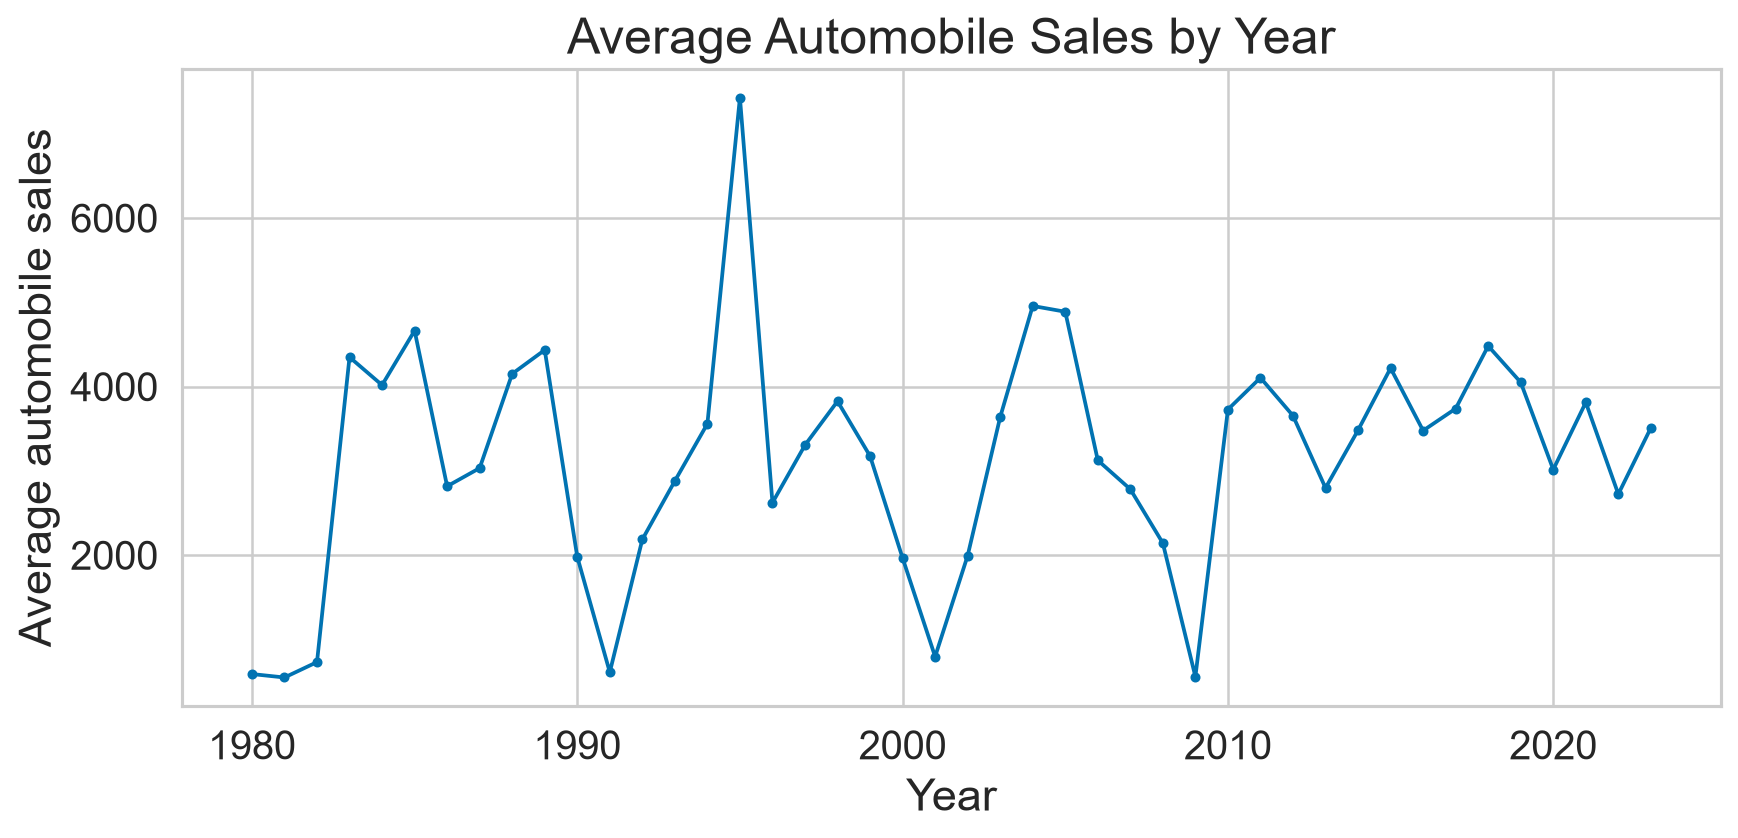

In [6]:
annual_sales = df.groupby("Year")["Automobile_Sales"].mean()
annual_sales.plot(kind="line", marker="o", markersize=3)
plt.xlabel("Year"); plt.ylabel("Average automobile sales")
plt.title("Average Automobile Sales by Year")
plt.tight_layout(); plt.show()

### Include the following on the plot
ticks on x- axis with all the years, to identify the years of recession 
<br>annotation for at least two years of recession
<br>Title as Automobile Sales during Recession
<br> 


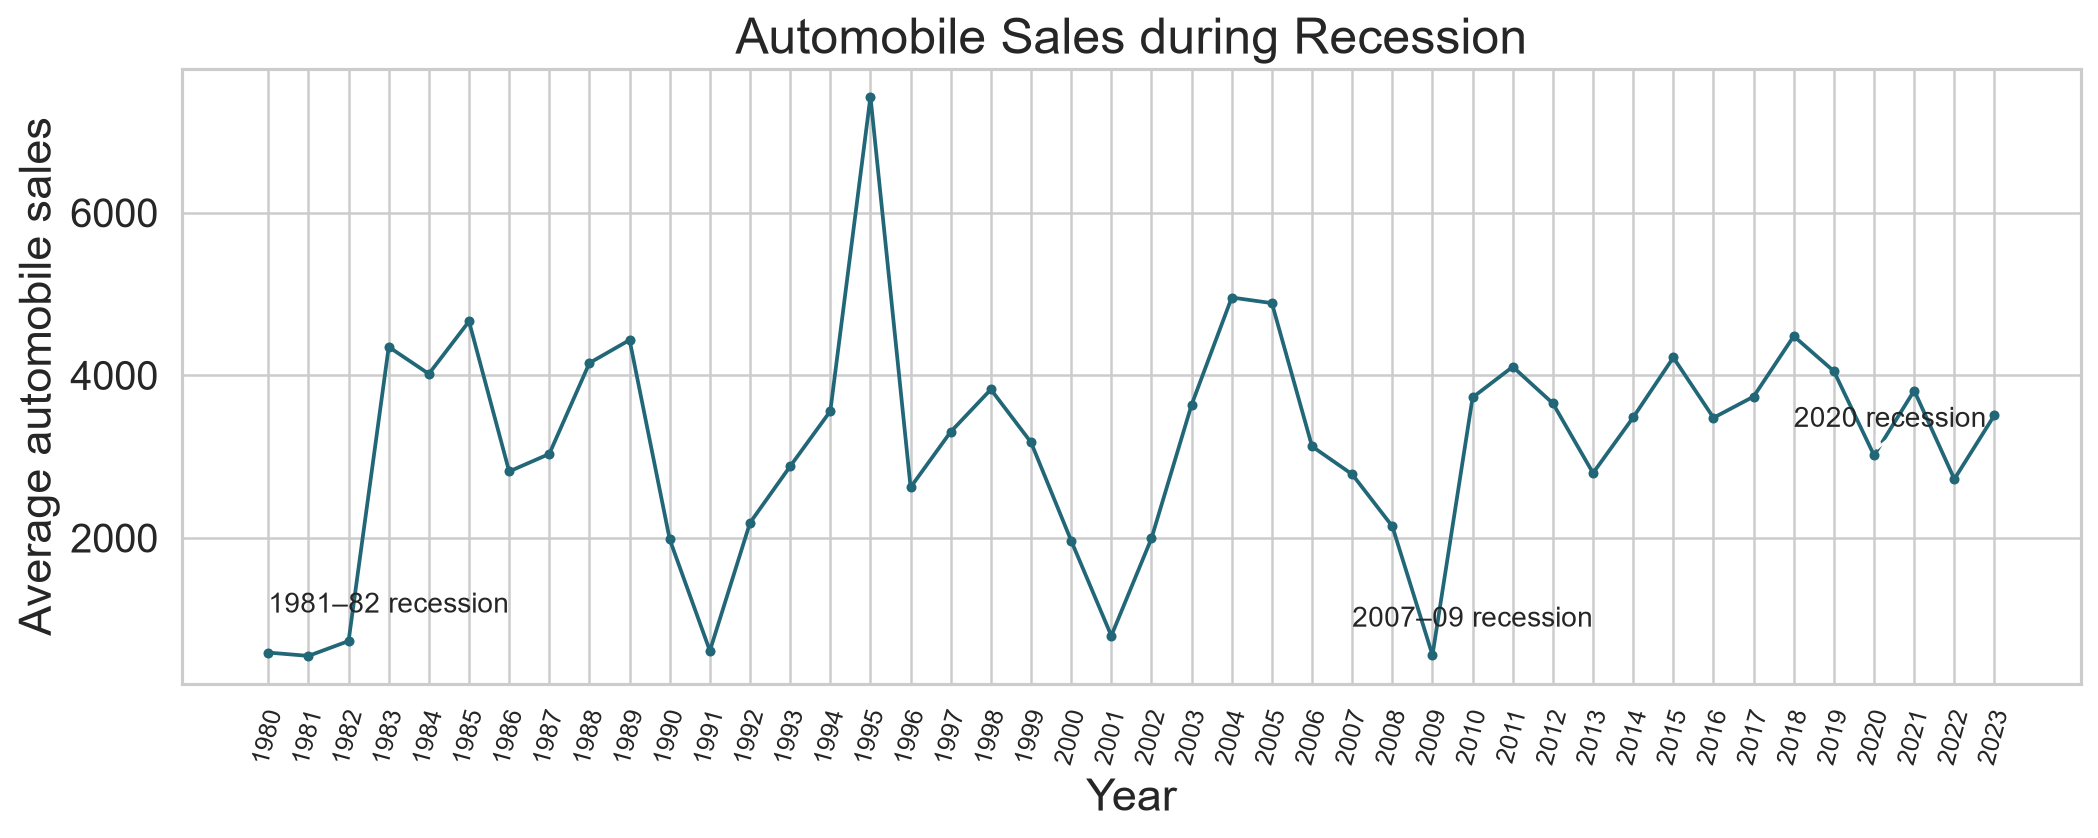

Lowest annual mean: 1981 (549.2); highest: 1995 (7429.7).
Annual means include both recession and non-recession observations in mixed years; the annotations identify recession years rather than changing the data filter.


In [7]:
annual_sales.plot(kind="line", figsize=(12, 5), color="#216778", marker="o", markersize=3)
plt.xticks(range(1980, 2024), rotation=75, fontsize=10)
for year, label in [(1982, "1981–82 recession"), (2009, "2007–09 recession"), (2020, "2020 recession")]:
    plt.annotate(label, xy=(year, annual_sales.loc[year]), xytext=(year-2, annual_sales.loc[year]+350), arrowprops={"arrowstyle":"->"}, fontsize=11)
plt.xlabel("Year"); plt.ylabel("Average automobile sales")
plt.title("Automobile Sales during Recession")
plt.tight_layout(); plt.show()
print(f"Lowest annual mean: {annual_sales.idxmin()} ({annual_sales.min():.1f}); highest: {annual_sales.idxmax()} ({annual_sales.max():.1f}).")
print("Annual means include both recession and non-recession observations in mixed years; the annotations identify recession years rather than changing the data filter.")

---



####  TASK 1.2: How do trends in advertising expenditure correlate with automobile sales during non-recession periods, and what insights can be derived from this relationship.


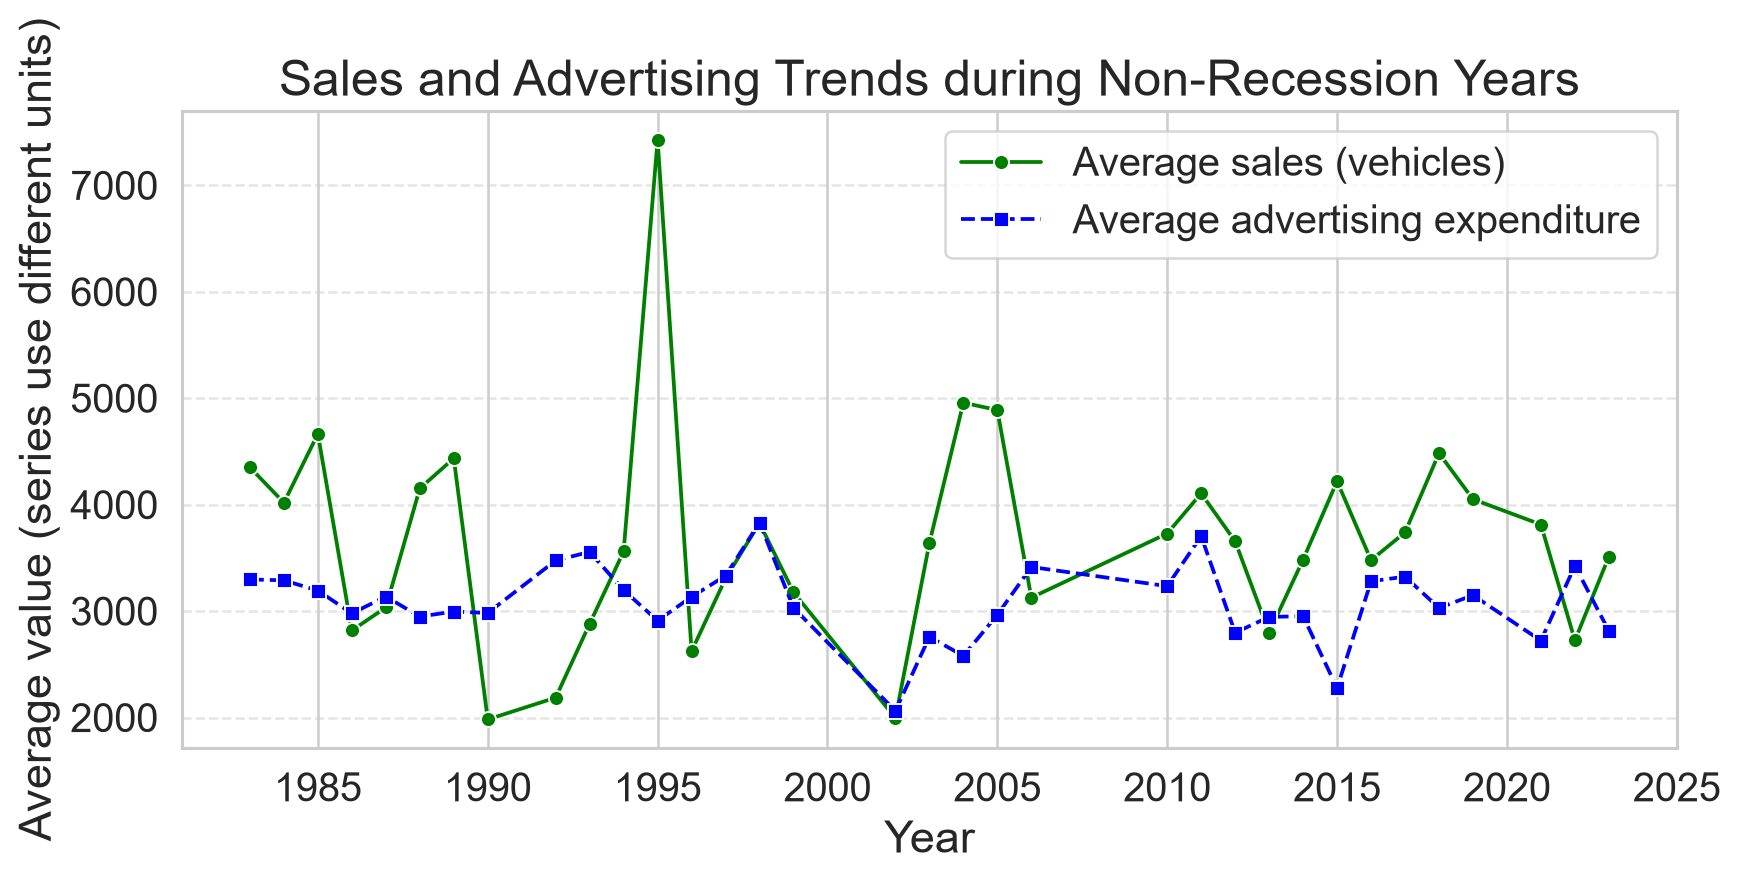

In [8]:
non_rec = df[df["Recession"] == 0]
trends = non_rec.groupby("Year")[["Automobile_Sales", "Advertising_Expenditure"]].mean().reset_index()
sns.lineplot(data=trends, x="Year", y="Automobile_Sales", color="green", marker="o", linestyle="-", label="Average sales (vehicles)")
sns.lineplot(data=trends, x="Year", y="Advertising_Expenditure", color="blue", marker="s", linestyle="--", label="Average advertising expenditure")
plt.xlabel("Year"); plt.ylabel("Average value (series use different units)")
plt.title("Sales and Advertising Trends during Non-Recession Years")
plt.grid(axis="y", linestyle="--", alpha=.5); plt.legend()
plt.tight_layout(); plt.show()

#### From the above plot, what insights have you gained?<br> Type in your answer below:


In [9]:
r = trends["Automobile_Sales"].corr(trends["Advertising_Expenditure"])
display(Markdown(f"**My interpretation.** Across the non-recession annual averages, sales and advertising expenditure have Pearson correlation **{r:.3f}**, indicating almost no linear association. Sales reach their highest annual average in **{int(trends.loc[trends['Automobile_Sales'].idxmax(), 'Year'])}**, whereas advertising peaks in **{int(trends.loc[trends['Advertising_Expenditure'].idxmax(), 'Year'])}**. The two series therefore do not rise and fall together consistently. Their heights use different units, so visual proximity alone is not a useful comparison."))

**My interpretation.** Across the non-recession annual averages, sales and advertising expenditure have Pearson correlation **-0.069**, indicating almost no linear association. Sales reach their highest annual average in **1995**, whereas advertising peaks in **1998**. The two series therefore do not rise and fall together consistently. Their heights use different units, so visual proximity alone is not a useful comparison.

----


### TASK 1.3: Use the functionality of **Seaborn Library** to create a visualization to compare the sales trend per vehicle type for a recession period with a non-recession period.


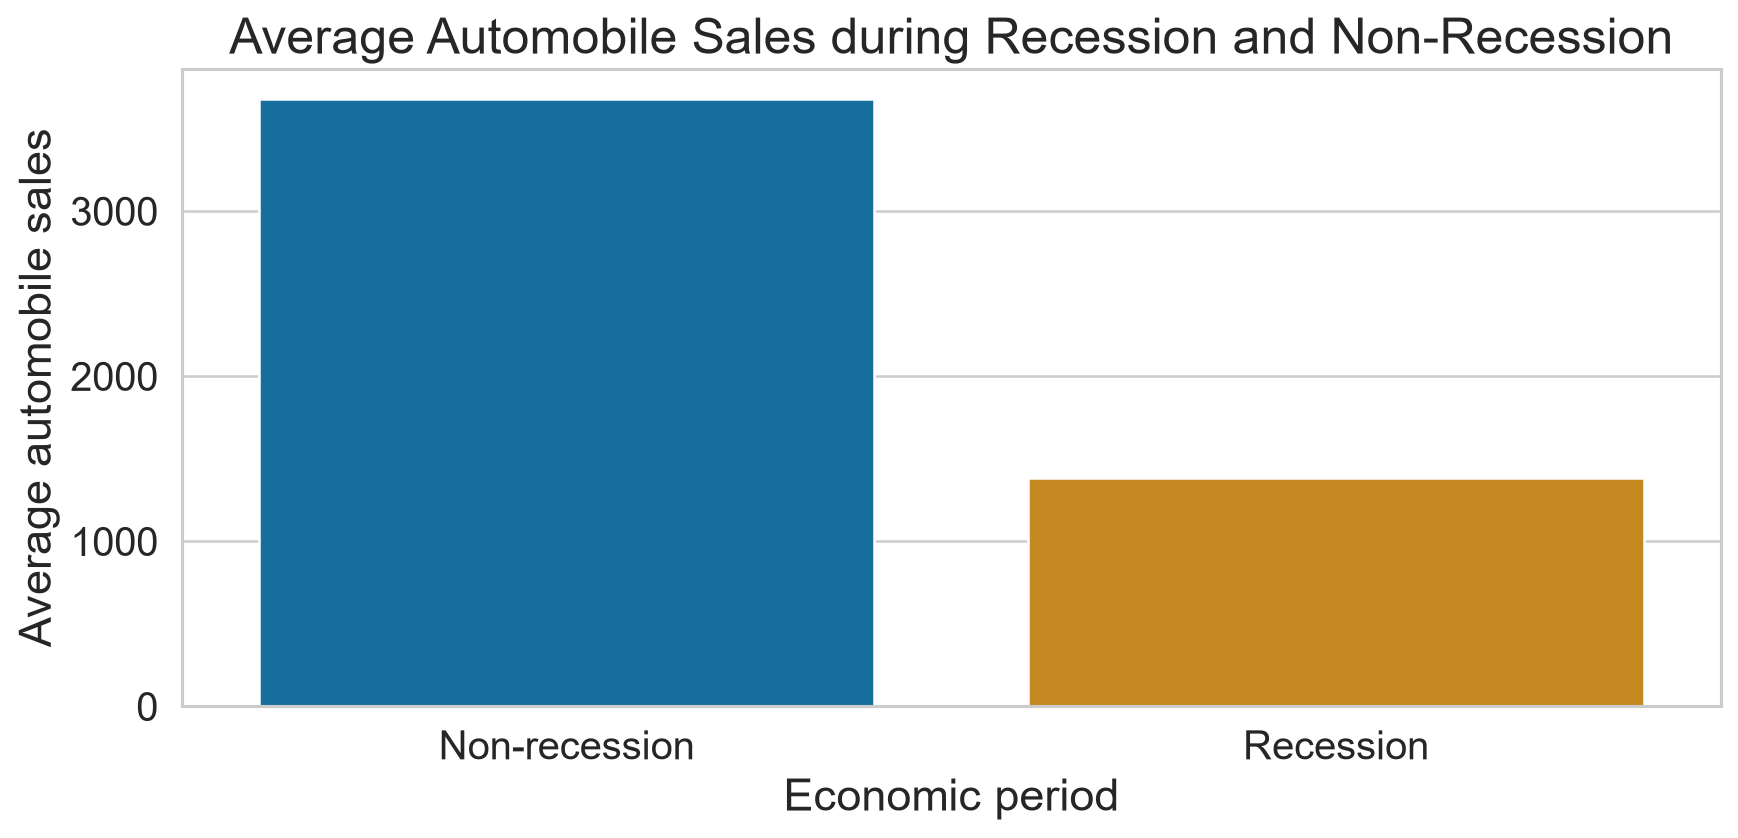

In [10]:
overall = df.groupby("Recession", as_index=False)["Automobile_Sales"].mean()
sns.barplot(data=overall, x="Recession", y="Automobile_Sales", hue="Recession", palette="colorblind", legend=False)
plt.xticks([0, 1], ["Non-recession", "Recession"])
plt.xlabel("Economic period"); plt.ylabel("Average automobile sales")
plt.title("Average Automobile Sales during Recession and Non-Recession")
plt.tight_layout(); plt.show()

### Now you want to compare the sales of different vehicle types during a recession and a non-recession period
<br>We recommend that you use the functionality of **Seaborn Library** to create this visualization


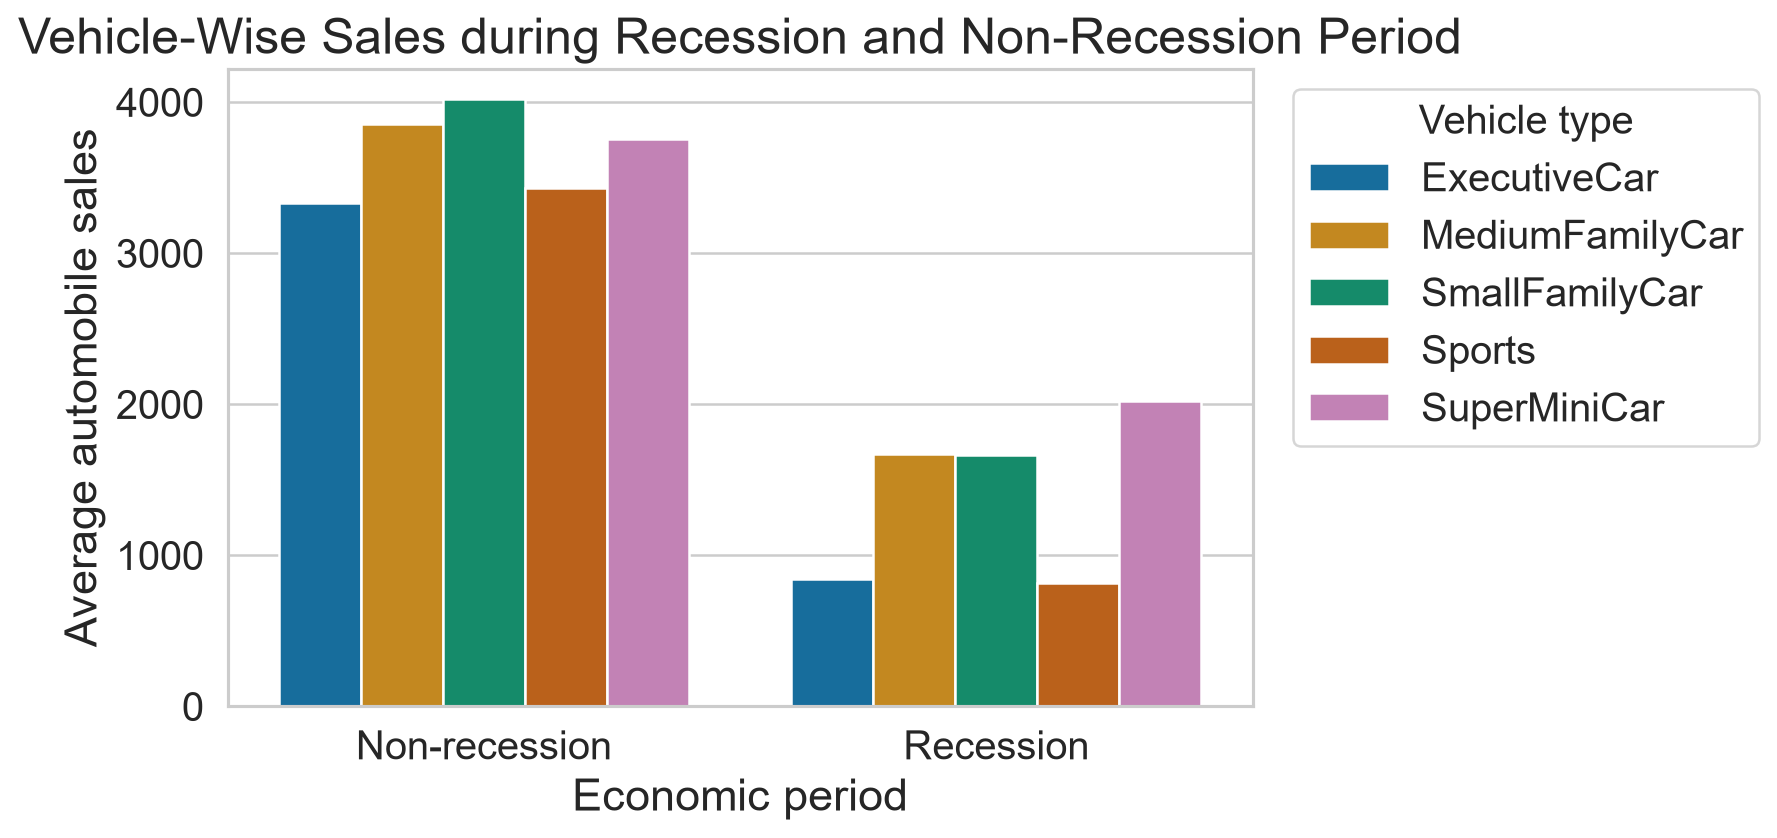

,Non-recession mean,Recession mean,Change (%)
Vehicle_Type,,,
ExecutiveCar,3332.3,842.1,-74.7
MediumFamilyCar,3853.4,1673.0,-56.6
SmallFamilyCar,4021.9,1662.7,-58.7
Sports,3431.0,814.8,-76.3
SuperMiniCar,3754.3,2019.3,-46.2


Recession mean relative to non-recession mean: -62.5%.


In [11]:
vehicle_sales = df.groupby(["Recession", "Vehicle_Type"], as_index=False)["Automobile_Sales"].mean()
sns.barplot(data=vehicle_sales, x="Recession", y="Automobile_Sales", hue="Vehicle_Type")
plt.xticks([0, 1], ["Non-recession", "Recession"])
plt.xlabel("Economic period"); plt.ylabel("Average automobile sales")
plt.title("Vehicle-Wise Sales during Recession and Non-Recession Period")
plt.legend(title="Vehicle type", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout(); plt.show()
comparison = vehicle_sales.pivot(index="Vehicle_Type", columns="Recession", values="Automobile_Sales")
comparison.columns = ["Non-recession mean", "Recession mean"]
comparison["Change (%)"] = (comparison["Recession mean"] / comparison["Non-recession mean"] - 1) * 100
display(comparison.round(1))
mean_rec = overall.set_index("Recession")["Automobile_Sales"]
print(f"Recession mean relative to non-recession mean: {(mean_rec[1]/mean_rec[0]-1)*100:.1f}%.")

### From the above chart what insights have you gained on the overall sales of automobiles during recession? <br> Type your answer below:-


**My interpretation.** Mean sales during recession are **62.5% lower** than in non-recession observations. **Sports** has the largest relative decline (**76.3%**). SuperMiniCar has the highest recession-period mean, while Sports and ExecutiveCar have much lower means. The grouped chart shows that the overall decline is shared across vehicle categories rather than being confined to one type.

---


### TASK 1.4: Use sub plotting to compare the variations in GDP during recession and non-recession period by developing line plots for each period.
<br>Now, you want to find more insights from the data to understand the reason. <br>Plot a two line charts using subplotting to answer:-
#### How did the GDP vary over time during recession and non-recession periods? 
<br>Make use of <u>add_subplot()</u> from Matplotlib for this comparision.


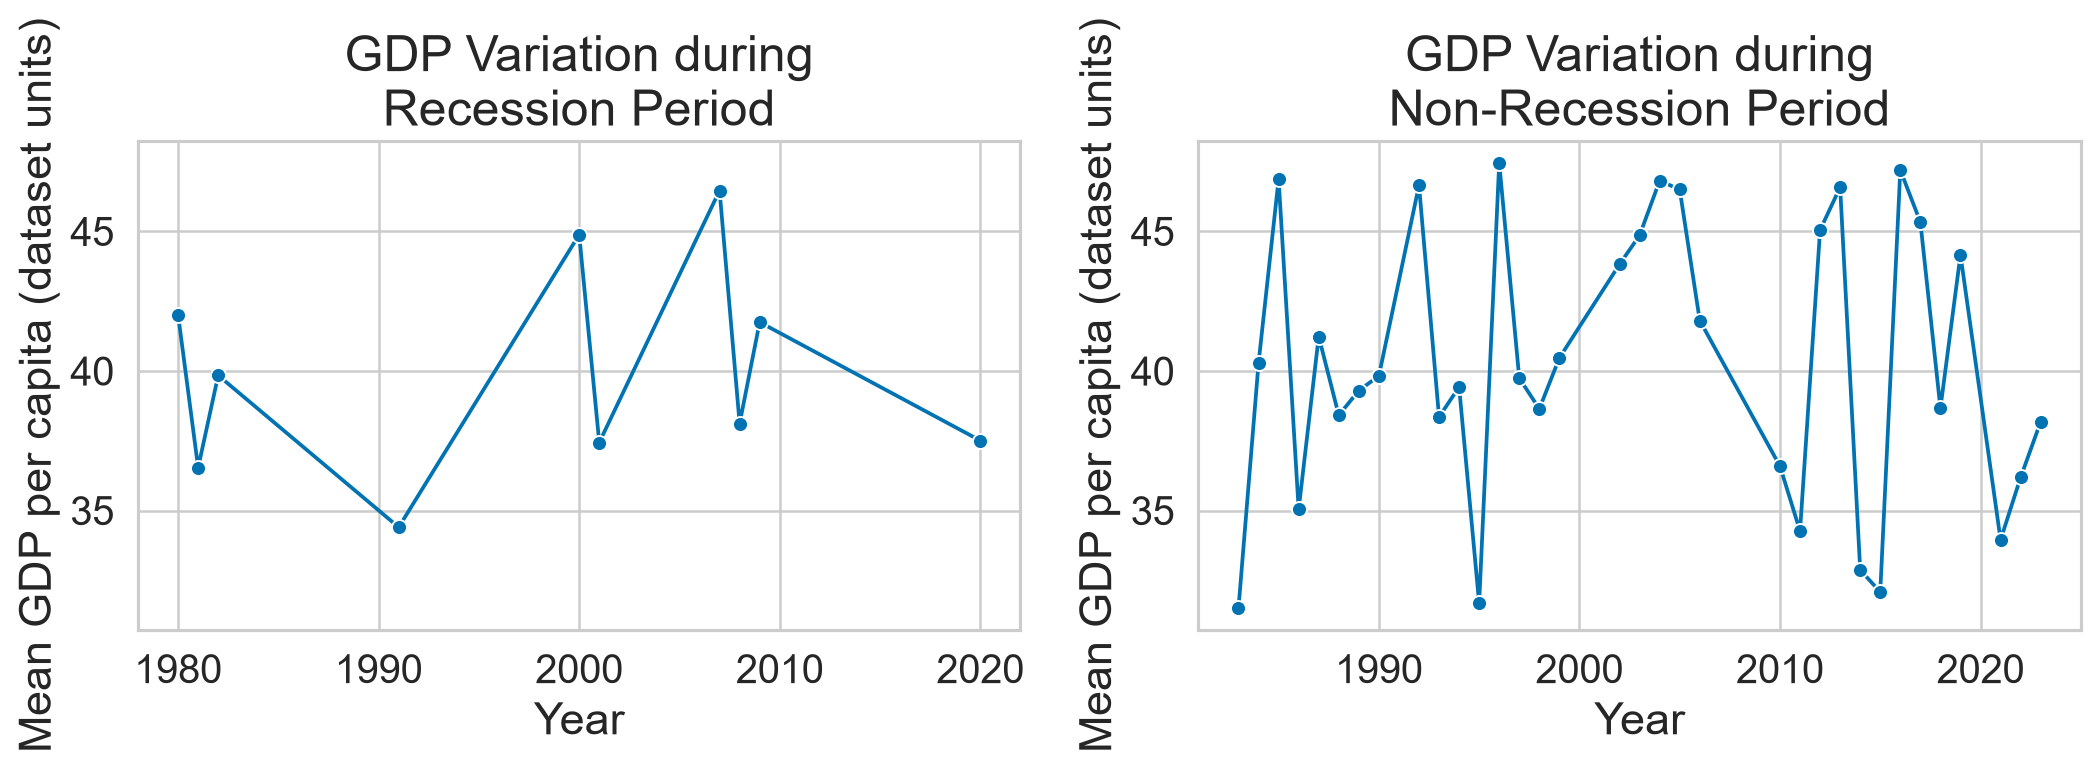

Mean GDP: recession 39.96; non-recession 40.28.
The shared y-axis supports comparison. Lines connect available years and do not imply every intervening year belongs to the same economic period.


In [12]:
rec = df[df["Recession"] == 1]
non_rec = df[df["Recession"] == 0]
fig = plt.figure(figsize=(12, 4.5))
ax0 = fig.add_subplot(1, 2, 1)
ax1 = fig.add_subplot(1, 2, 2, sharey=ax0)
for frame, ax, label in [(rec, ax0, "Recession"), (non_rec, ax1, "Non-Recession")]:
    annual_gdp = frame.groupby("Year", as_index=False)["GDP"].mean()
    sns.lineplot(data=annual_gdp, x="Year", y="GDP", marker="o", ax=ax)
    ax.set(xlabel="Year", ylabel="Mean GDP per capita (dataset units)", title=f"GDP Variation during\n{label} Period")
plt.tight_layout(); plt.show()
print(f"Mean GDP: recession {rec['GDP'].mean():.2f}; non-recession {non_rec['GDP'].mean():.2f}.")
print("The shared y-axis supports comparison. Lines connect available years and do not imply every intervening year belongs to the same economic period.")

---


### TASK 1.5: Develop a Bubble plot for displaying the impact of seasonality on Automobile Sales.
<br>How has seasonality impacted the sales, in which months the sales were high or low? Check it for non-recession years to understand the trend

##### Develop a Bubble plot for displaying Automobile Sales for every month and use Seasonality Weight for representing the size of each bubble<br>
Title this plot as 'Seasonality impact on Automobile Sales'


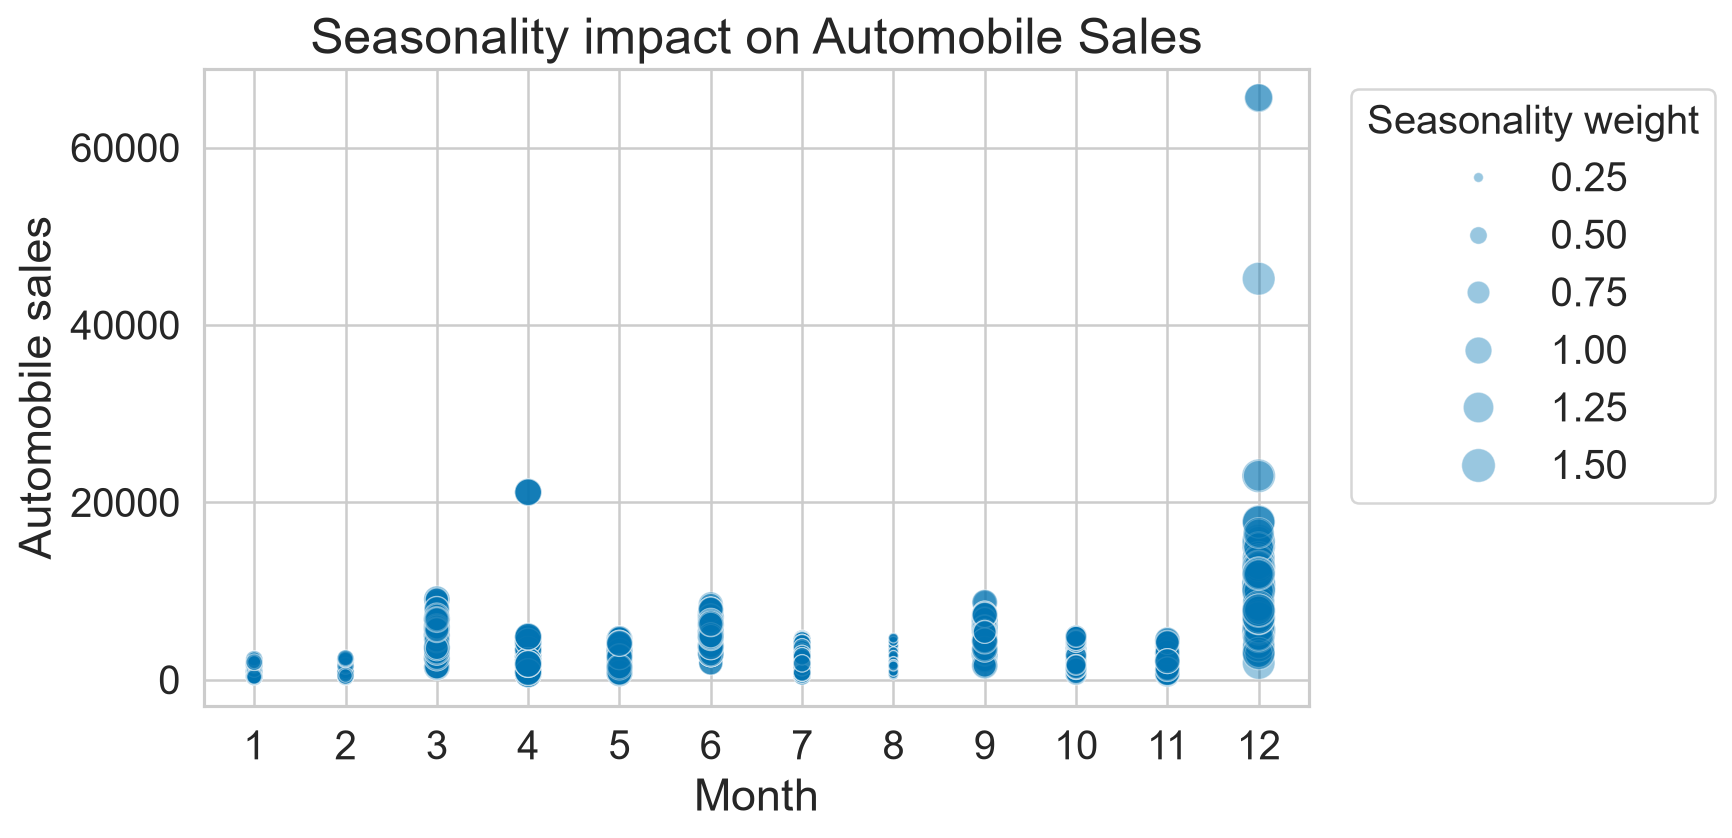

Highest monthly mean: month 12 (9729.1); lowest: month 1 (1253.8).
December stands out well above the other months; March, June and September also have relatively high averages. January and February are the lowest. Bubble size represents the supplied seasonality weight, while vertical position represents observed sales.


In [13]:
non_rec = df[df["Recession"] == 0].copy()
non_rec["Month_number"] = non_rec["Date"].dt.month
sns.scatterplot(data=non_rec, x="Month_number", y="Automobile_Sales", size="Seasonality_Weight", sizes=(15, 180), alpha=.4)
plt.xticks(range(1, 13)); plt.xlabel("Month"); plt.ylabel("Automobile sales")
plt.title("Seasonality impact on Automobile Sales")
plt.legend(title="Seasonality weight", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout(); plt.show()
season = non_rec.groupby("Month_number")["Automobile_Sales"].mean()
print(f"Highest monthly mean: month {season.idxmax()} ({season.max():.1f}); lowest: month {season.idxmin()} ({season.min():.1f}).")
print("December stands out well above the other months; March, June and September also have relatively high averages. January and February are the lowest. Bubble size represents the supplied seasonality weight, while vertical position represents observed sales.")

---


 ### TASK 1.6: Use the functionality of Matplotlib to develop a scatter plot to identify the relationship between consumer confidence and automobile sales during recessions.
 #### From the data, develop a scatter plot to identify the relationship between consumer confidence and automobile sales during recession periods.
 <br> Title this plot as 'Consumer Confidence and Automobile Sales during Recessions'


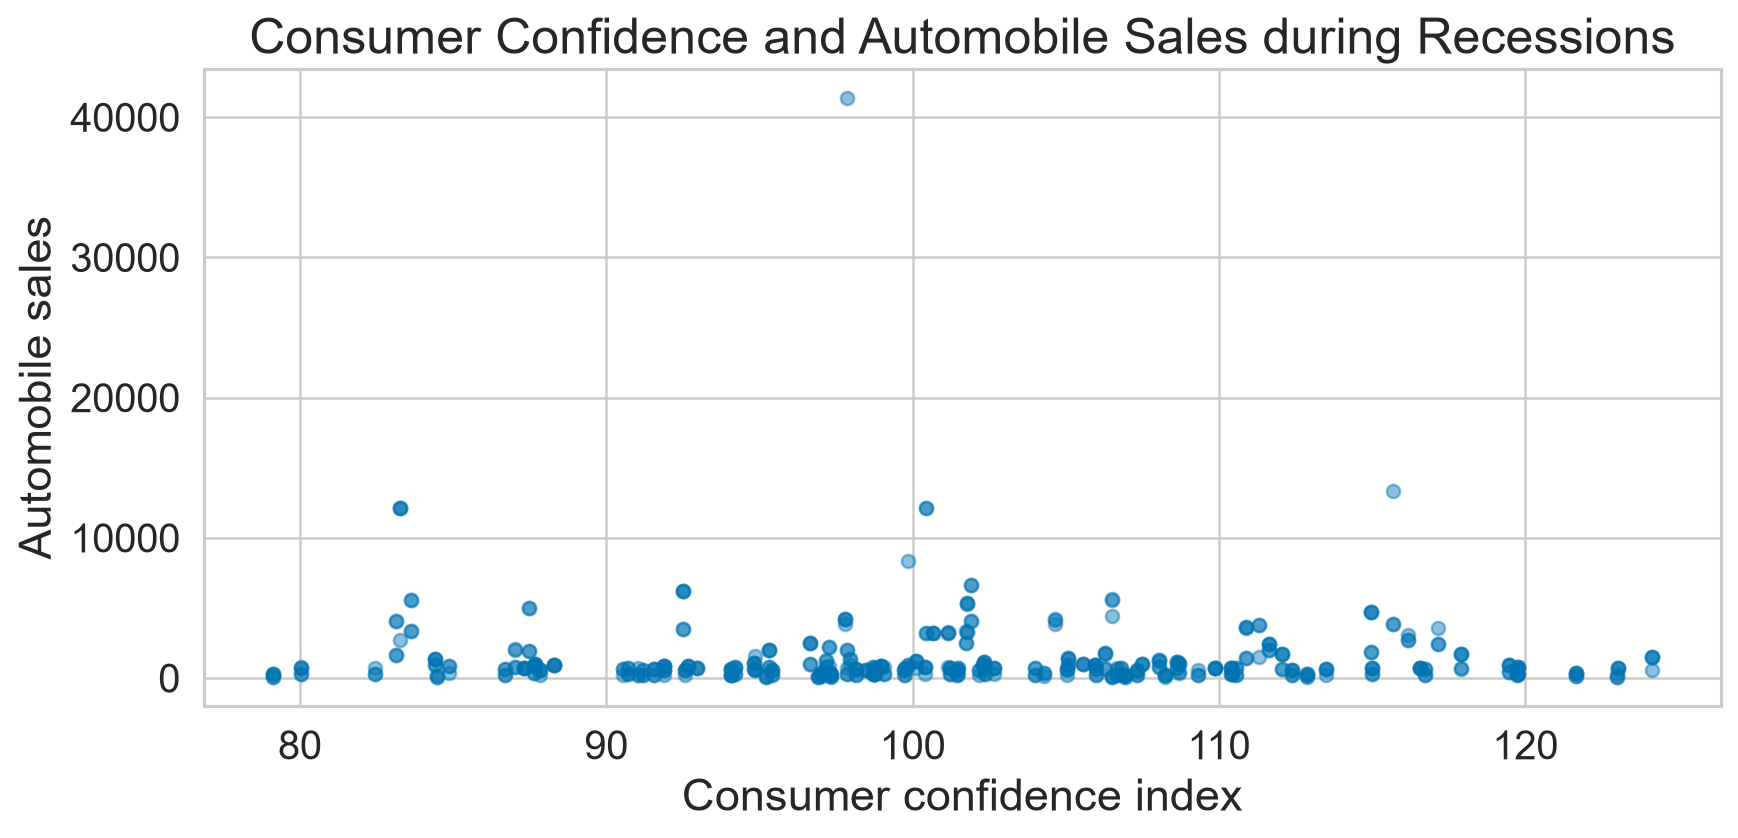

Pearson correlation: -0.050.
Consumer confidence has essentially no linear association with sales in these pooled recession observations. The plotted data do not support a strong positive relationship.


In [14]:
rec = df[df["Recession"] == 1]
plt.scatter(rec["Consumer_Confidence"], rec["Automobile_Sales"], alpha=.45, s=28)
plt.xlabel("Consumer confidence index"); plt.ylabel("Automobile sales")
plt.title("Consumer Confidence and Automobile Sales during Recessions")
plt.tight_layout(); plt.show()
print(f"Pearson correlation: {rec['Consumer_Confidence'].corr(rec['Automobile_Sales']):.3f}.")
print("Consumer confidence has essentially no linear association with sales in these pooled recession observations. The plotted data do not support a strong positive relationship.")


 ### How does consumer confidence relate to automobile sales during recessions?
 <br> Plot another scatter plot and title it as 'Relationship between Vehicle Price and Sales during Recessions'


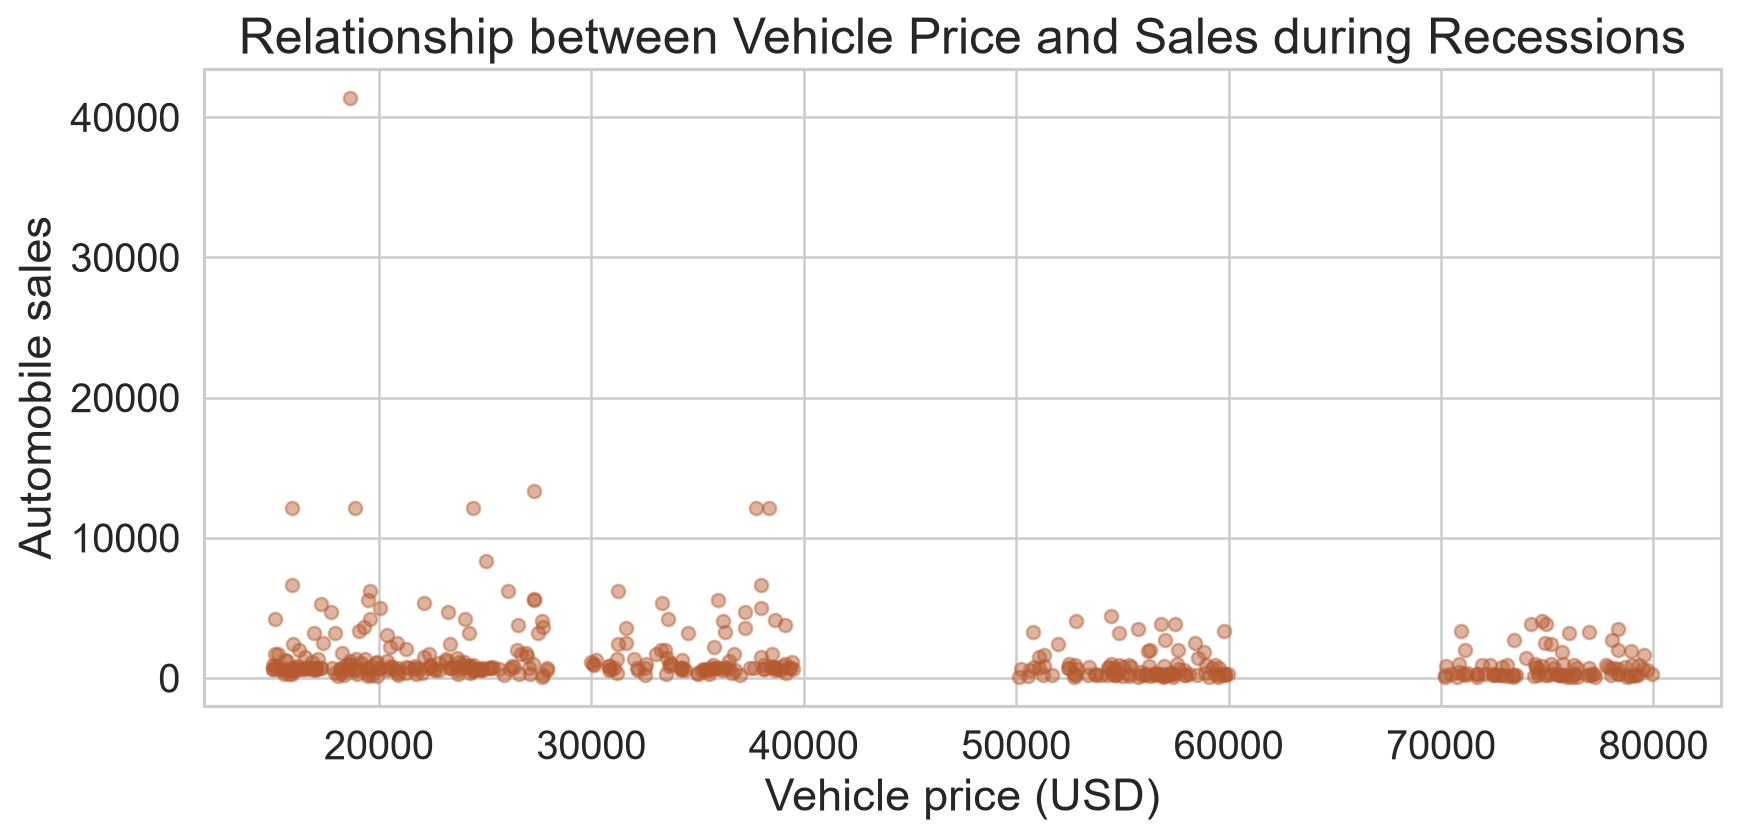

Pearson correlation: -0.167.
Price has a weak negative relationship with sales, stronger than the nearly flat confidence relationship. Lower-priced observations span a wide range of sales, while many high-priced observations have lower sales. The separate price bands also reflect the mix of vehicle categories.


In [15]:
plt.scatter(rec["Price"], rec["Automobile_Sales"], alpha=.45, s=28, color="#b55a30")
plt.xlabel("Vehicle price (USD)"); plt.ylabel("Automobile sales")
plt.title("Relationship between Vehicle Price and Sales during Recessions")
plt.tight_layout(); plt.show()
print(f"Pearson correlation: {rec['Price'].corr(rec['Automobile_Sales']):.3f}.")
print("Price has a weak negative relationship with sales, stronger than the nearly flat confidence relationship. Lower-priced observations span a wide range of sales, while many high-priced observations have lower sales. The separate price bands also reflect the mix of vehicle categories.")

----


 ### TASK 1.7: Create a pie chart to display the portion of advertising expenditure of XYZAutomotives during recession and non-recession periods.
 <br>How did the advertising expenditure of XYZAutomotives change during recession and non-recession periods? 


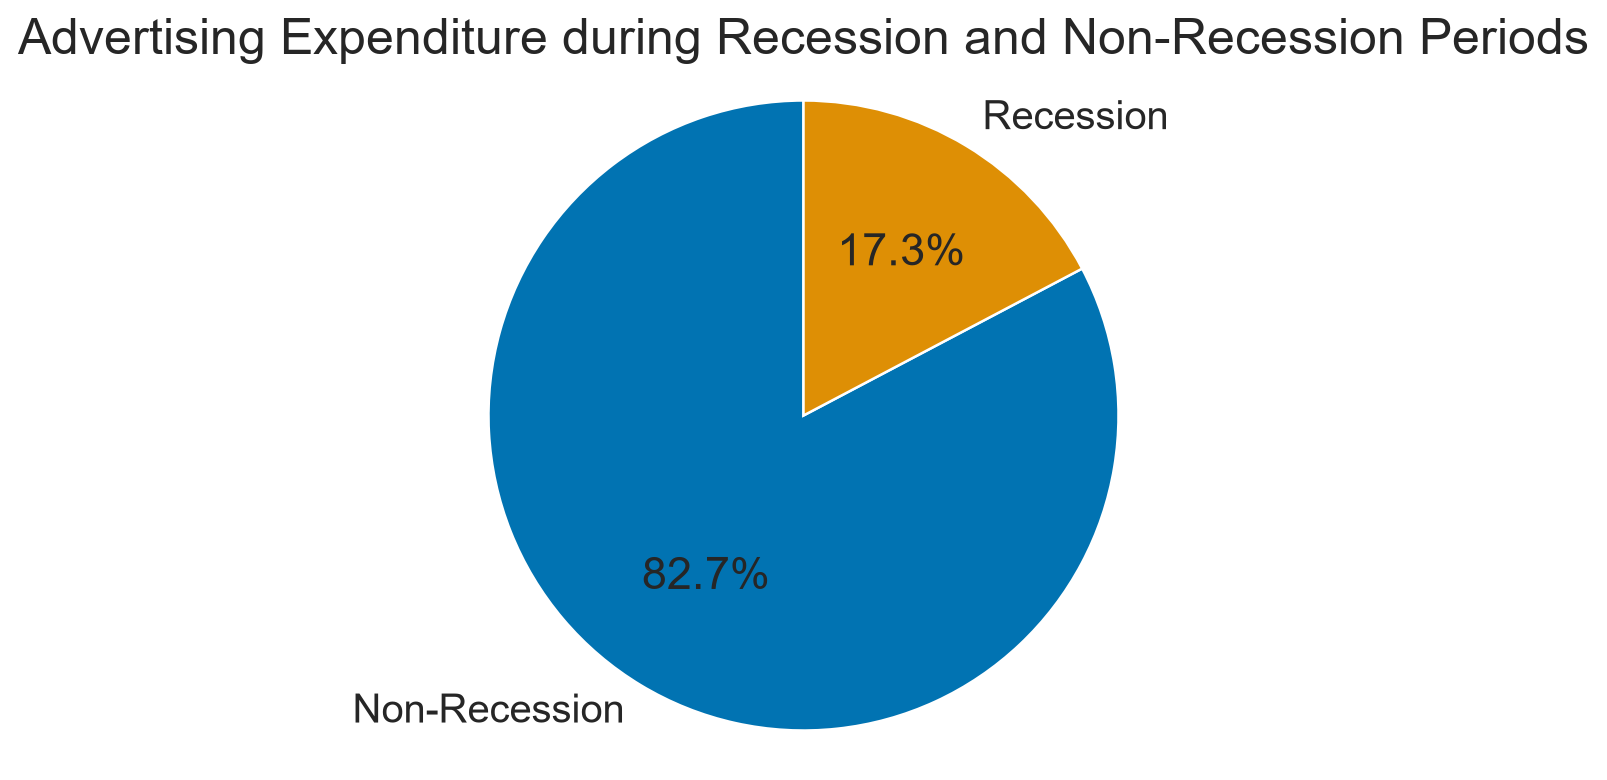

,size,sum,mean
Recession,,,
0,1638,5031103.0,3071.49
1,474,1050915.6,2217.12


In [16]:
ad_totals = df.groupby("Recession")["Advertising_Expenditure"].sum()
plt.figure(figsize=(8, 5))
plt.pie(ad_totals, labels=["Non-Recession", "Recession"], autopct="%1.1f%%", startangle=90)
plt.title("Advertising Expenditure during Recession and Non-Recession Periods")
plt.axis("equal"); plt.show()
display(df.groupby("Recession")["Advertising_Expenditure"].agg(["size", "sum", "mean"]).round(2))

#### From the above plot, what insights do you find on the advertisement expenditure during recession and non recession periods?<br> Type your answer below:-


**My interpretation.** Recession observations account for **17.3%** of total advertising expenditure. This is a total over unequal numbers of observations, so the pie alone does not establish the typical spending rate in either period. The table gives both the total and the mean to make that distinction visible.

---


### TASK 1.8: Develop a pie chart to display the total Advertisement expenditure for each vehicle type during recession period.<br>
Can we observe the share of each vehicle type in total expenditure during recessions? 


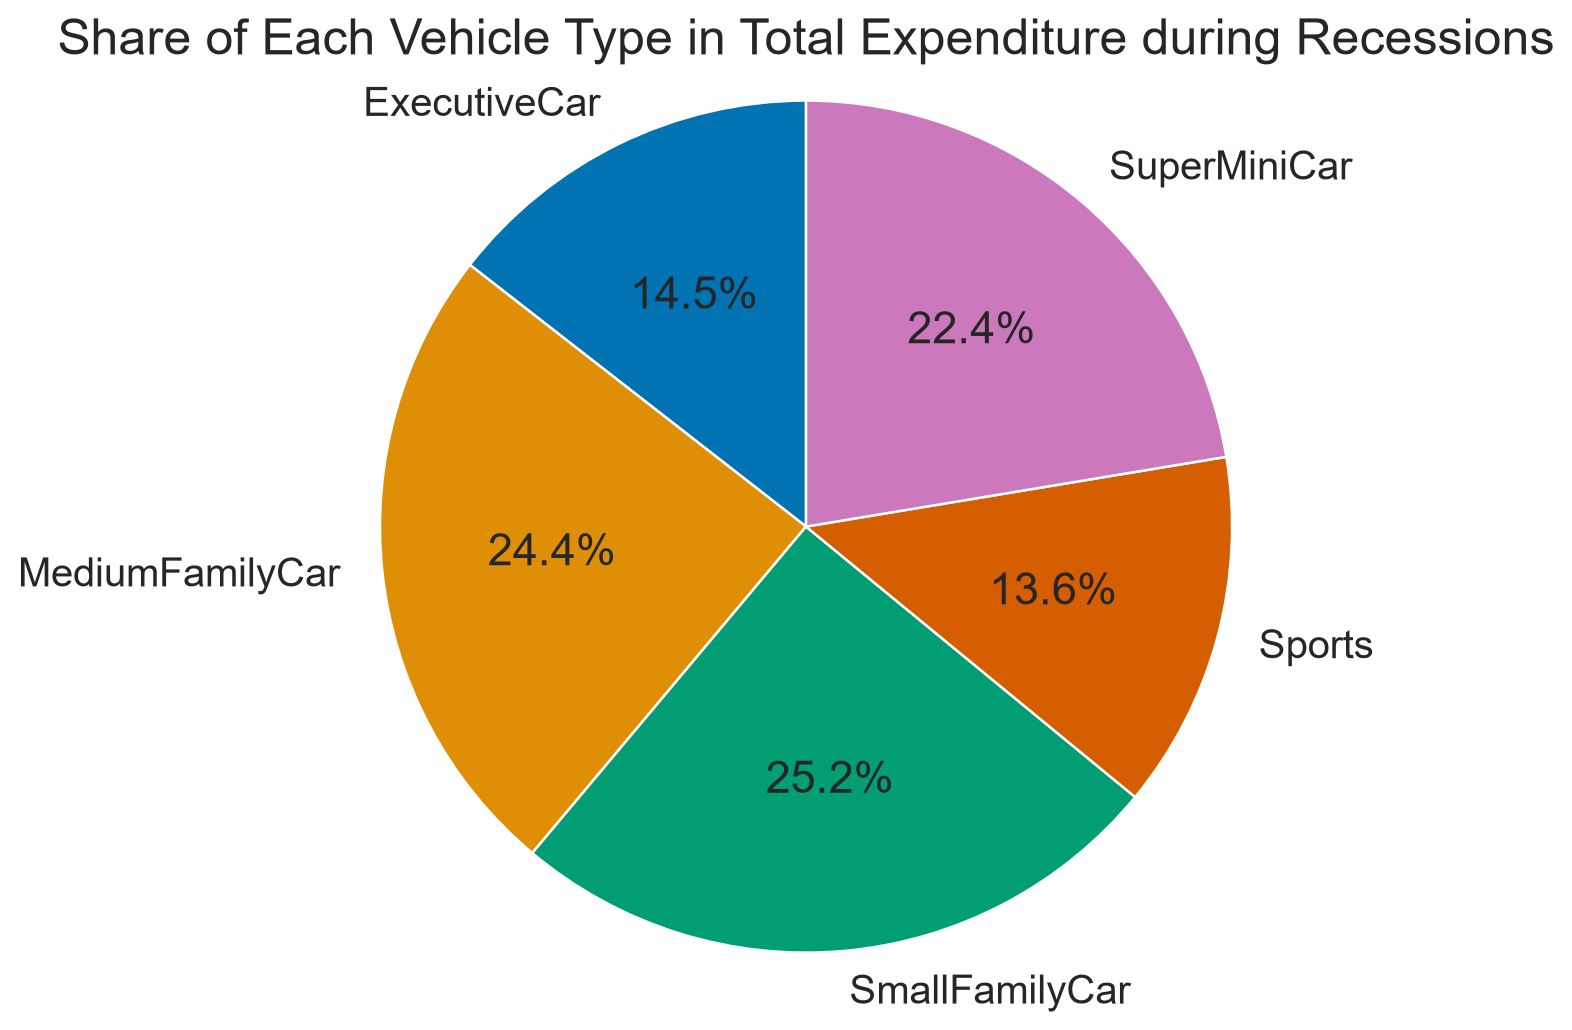

Largest advertising share: SmallFamilyCar (25.2%).
SmallFamilyCar and MediumFamilyCar together receive 49.6% of recession advertising. Sports has the smallest share, while SuperMiniCar receives more than either Sports or ExecutiveCar.


In [17]:
ad_by_type = rec.groupby("Vehicle_Type")["Advertising_Expenditure"].sum()
plt.figure(figsize=(9, 6))
plt.pie(ad_by_type, labels=ad_by_type.index, autopct="%1.1f%%", startangle=90)
plt.title("Share of Each Vehicle Type in Total Expenditure during Recessions")
plt.axis("equal"); plt.tight_layout(); plt.show()
print(f"Largest advertising share: {ad_by_type.idxmax()} ({ad_by_type.max()/ad_by_type.sum()*100:.1f}%).")
print(f"SmallFamilyCar and MediumFamilyCar together receive {(ad_by_type['SmallFamilyCar']+ad_by_type['MediumFamilyCar'])/ad_by_type.sum()*100:.1f}% of recession advertising. Sports has the smallest share, while SuperMiniCar receives more than either Sports or ExecutiveCar.")

----


 ### TASK 1.9: Develop a lineplot to analyse the effect of the unemployment rate on vehicle type and sales during the Recession Period.
 <br>Analyze the effect of the unemployment rate on vehicle type and sales during the Recession Period
 #### You can create a lineplot and title the plot as 'Effect of Unemployment Rate on Vehicle Type and Sales'


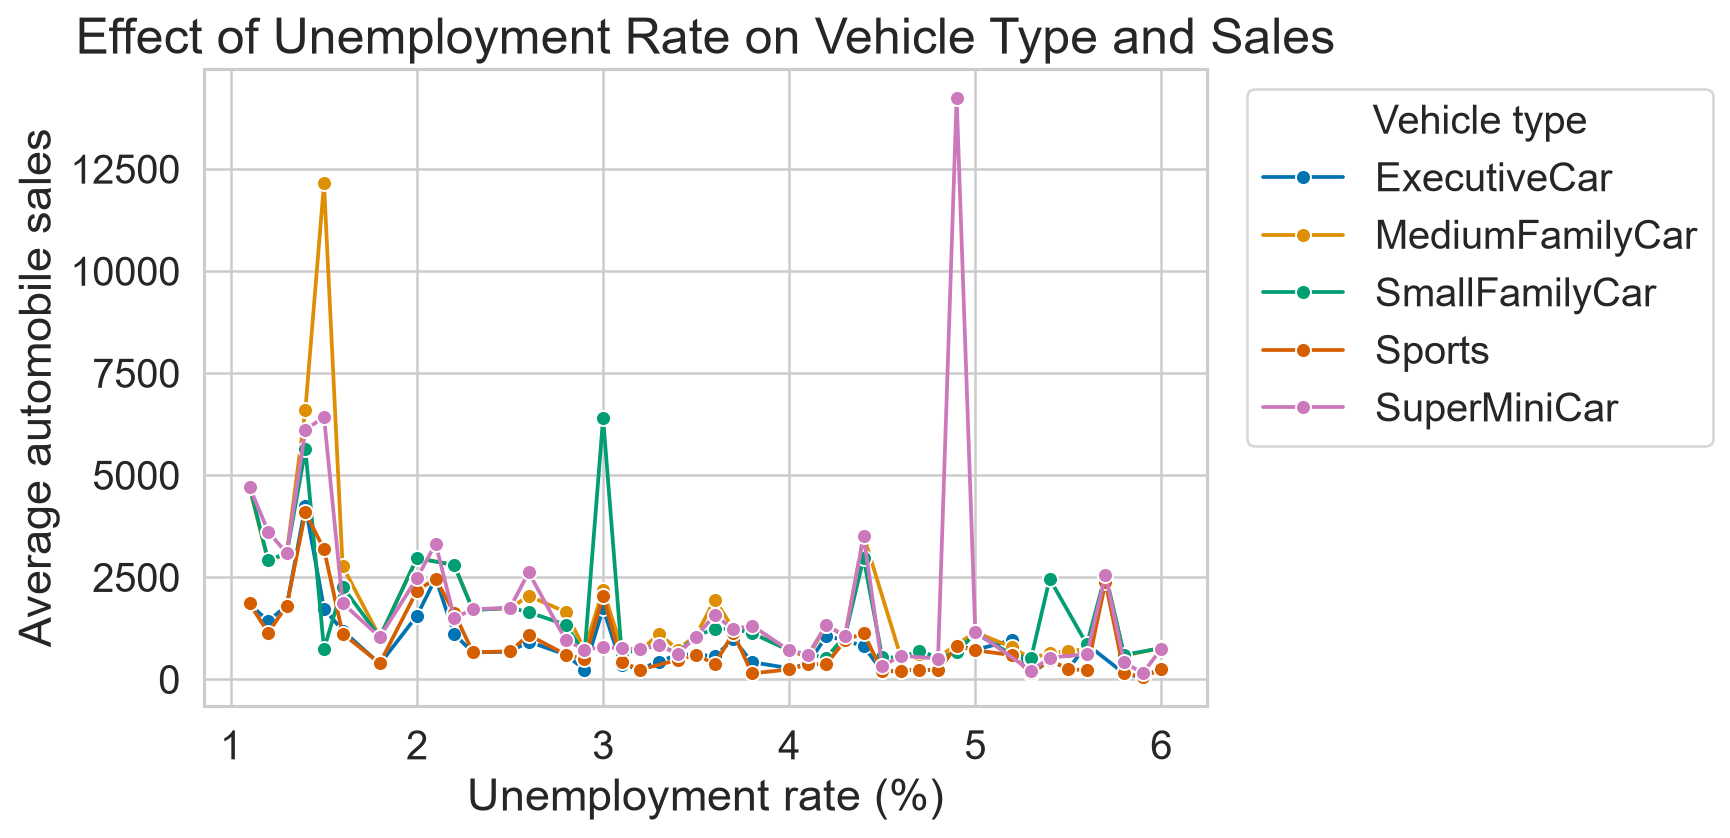

,Mean sales,Unemployment-sales correlation
Vehicle type,,
ExecutiveCar,842.056,-0.414
MediumFamilyCar,1672.964,-0.366
SmallFamilyCar,1662.741,-0.217
Sports,814.776,-0.357
SuperMiniCar,2019.327,-0.074


In [18]:
unemployment_sales = rec.groupby(["unemployment_rate", "Vehicle_Type"], as_index=False)["Automobile_Sales"].mean()
sns.lineplot(data=unemployment_sales, x="unemployment_rate", y="Automobile_Sales", hue="Vehicle_Type", marker="o")
plt.xlabel("Unemployment rate (%)"); plt.ylabel("Average automobile sales")
plt.title("Effect of Unemployment Rate on Vehicle Type and Sales")
plt.legend(title="Vehicle type", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout(); plt.show()
summary = []
for vehicle, observations in rec.groupby("Vehicle_Type"):
    summary.append({"Vehicle type": vehicle,
                    "Mean sales": observations["Automobile_Sales"].mean(),
                    "Unemployment-sales correlation": observations["unemployment_rate"].corr(observations["Automobile_Sales"])})
display(pd.DataFrame(summary).set_index("Vehicle type").round(3))

#### From the above plot, what insights have you gained on the sales of superminicar, smallfamilycar, mediumminicar?<br> Type your answer below:-


**My interpretation.** SuperMiniCar has the highest recession-period mean sales (**2,019.3**), followed by MediumFamilyCar (**1,673.0**) and SmallFamilyCar (**1,662.7**). ExecutiveCar (**842.1**) and Sports (**814.8**) are much lower. SmallFamilyCar and MediumFamilyCar sales generally move downward as unemployment rises, with within-type correlations of **−0.217** and **−0.366**, respectively. Their lines are not monotonic: sales still rise at some individual rates. SuperMiniCar has a much weaker association (**−0.074**) and retains a higher sales level across much of the plotted range.

---


### OPTIONAL : TASK 1.10 Create a map on the hightest sales region/offices of the company during recession period


In [19]:
import json
states = json.loads((DATA / "us-states.json").read_text())
print(f"Loaded {len(states['features'])} geographic features from the local GeoJSON.")

Loaded 50 geographic features from the local GeoJSON.


#### You found that the datset also contains the location/city for company offices. Now you want to show the recession impact on various offices/city sales by developing a choropleth


In [20]:
sales_by_state = rec.groupby("City", as_index=False)["Automobile_Sales"].sum()
state_names = {feature["properties"]["name"] for feature in states["features"]}
assert set(sales_by_state["City"]).issubset(state_names)
print("Although the CSV column is named City, its values match US state names:")
display(sales_by_state.sort_values("Automobile_Sales", ascending=False).round(1))
sales_map = folium.Map(location=[37.0902, -95.7129], zoom_start=4, tiles="OpenStreetMap", height=560)
layer = folium.Choropleth(geo_data=states, data=sales_by_state, columns=["City", "Automobile_Sales"], key_on="feature.properties.name", fill_color="YlOrRd", fill_opacity=.75, line_opacity=.3, nan_fill_color="lightgray", legend_name="Total automobile sales in recession observations").add_to(sales_map)
folium.GeoJsonTooltip(fields=["name"], aliases=["State:"]).add_to(layer.geojson)
sales_map.save("Final_recession_sales_map.html")
print("Gray states have no observations, not zero sales. Totals also reflect unequal observation coverage.")
display(sales_map)

Although the CSV column is named City, its values match US state names:


,City,Automobile_Sales
0,California,185607.7
2,Illinois,174905.5
3,New York,163308.8
1,Georgia,131121.9


Gray states have no observations, not zero sales. Totals also reflect unequal observation coverage.
